# Group 12 — PLSA All-20 Topic-Count Study

This is a new model-order experiment on all 20 categories of 20 Newsgroups. It compares PLSA with K = 2, 5, 8, 10, and 20 while holding the corpus, split, preprocessing, vocabulary, queries, retrieval metrics, and baselines fixed.

The split is 60% training, 20% validation, and 20% test. Validation results select a K for each PLSA scoring method. Test results for every predeclared K are reported as a model-order comparison; do not use those test scores to retune the model. Category labels are used for splitting and evaluation only, not as PLSA training targets.


## 0. Install dependencies

Run once in a notebook environment if required. In Colab, use the first line in a code cell.

In [1]:
# %pip -q install numpy scipy scikit-learn pandas matplotlib

## 1. Imports and reproducibility

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)


## 2. Load the selected dataset

We load only the two categories selected for the topic-boundary experiment. The category labels are used for evaluation and for choosing source documents for synthetic mixtures; PLSA itself is unsupervised and does not receive these labels during training.

In [3]:
dataset = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=SEED
)
documents = np.array(dataset.data, dtype=object)
labels = np.asarray(dataset.target)
target_names = list(dataset.target_names)

print("Number of categories:", len(target_names))
print("Total documents:", len(documents))
for i, name in enumerate(target_names):
    print(f"{i:2d} | {name:25s} | {(labels == i).sum():5d} documents")


Number of categories: 20
Total documents: 18846
 0 | alt.atheism               |   799 documents
 1 | comp.graphics             |   973 documents
 2 | comp.os.ms-windows.misc   |   985 documents
 3 | comp.sys.ibm.pc.hardware  |   982 documents
 4 | comp.sys.mac.hardware     |   963 documents
 5 | comp.windows.x            |   988 documents
 6 | misc.forsale              |   975 documents
 7 | rec.autos                 |   990 documents
 8 | rec.motorcycles           |   996 documents
 9 | rec.sport.baseball        |   994 documents
10 | rec.sport.hockey          |   999 documents
11 | sci.crypt                 |   991 documents
12 | sci.electronics           |   984 documents
13 | sci.med                   |   990 documents
14 | sci.space                 |   987 documents
15 | soc.religion.christian    |   997 documents
16 | talk.politics.guns        |   910 documents
17 | talk.politics.mideast     |   940 documents
18 | talk.politics.misc        |   775 documents
19 | talk.religion.mi

### Main corpus versus boundary experiment

The model and retrieval evaluation use the **full 20-category corpus**. The controlled boundary experiment still uses two chosen source categories to create interpretable 90:10 through 10:90 word mixtures. This does not mean the PLSA model was trained on only those two categories.

## 3. Train/test split and preprocessing

Split the raw documents first. Fit the vocabulary only on the training split to avoid vocabulary leakage from the test documents.

In [4]:
import re
import spacy
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer


docs_train, docs_temp, y_train, y_temp = train_test_split(
    documents, labels, test_size=0.40, random_state=SEED, stratify=labels
)
docs_val, docs_test, y_val, y_test = train_test_split(
    docs_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

def preprocess_texts(texts):
    processed_docs = []
    for doc in nlp.pipe(texts, batch_size=256):
        tokens = []
        for token in doc:
            if token.is_space or token.is_punct or token.like_num or not token.is_alpha:
                continue
            if token.is_stop:
                continue
            lemma = token.lemma_.lower().strip()
            if len(lemma) >= 2:
                tokens.append(lemma)
        processed_docs.append(" ".join(tokens))
    return processed_docs

docs_train_processed = preprocess_texts(docs_train)
docs_val_processed = preprocess_texts(docs_val)
docs_test_processed = preprocess_texts(docs_test)

count_vectorizer = CountVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=3000, min_df=3, max_df=0.90, dtype=np.float64
)
X_train = count_vectorizer.fit_transform(docs_train_processed)
X_val = count_vectorizer.transform(docs_val_processed)
X_test = count_vectorizer.transform(docs_test_processed)
vocabulary = count_vectorizer.get_feature_names_out()

print("Documents train/validation/test:", len(docs_train), len(docs_val), len(docs_test))
print("Count matrices:", X_train.shape, X_val.shape, X_test.shape)
print("Empty docs train/validation/test:",
      sum(not x.strip() for x in docs_train_processed),
      sum(not x.strip() for x in docs_val_processed),
      sum(not x.strip() for x in docs_test_processed))


Documents train/validation/test: 11307 3769 3770
Count matrices: (11307, 3000) (3769, 3000) (3770, 3000)
Empty docs train/validation/test: 334 115 118


## 4. PLSA theory

For document \(d\), word \(w\), and latent topic \(z\):

\[
P(w\mid d)=\sum_{z=1}^{K}P(w\mid z)P(z\mid d)
\]

- \(\theta_{d,z}=P(z\mid d)\): document-topic distribution.
- \(\phi_{z,w}=P(w\mid z)\): topic-word distribution.
- Each row of \(\theta\) and \(\phi\) sums to one.

For every observed document-word pair, the E-step computes the posterior responsibility:

\[
P(z\mid d,w)=\frac{P(z\mid d)P(w\mid z)}
{\sum_{z'}P(z'\mid d)P(w\mid z')}
\]

The M-step uses the expected word counts to update both distributions. The process repeats until the log-likelihood stops improving.

In [5]:
class PLSA:
    """PLSA trained directly with NumPy EM and sparse input counts."""

    def __init__(self, n_topics=5, max_iter=100, tol=1e-4,
                 random_state=42, beta=1.0):
        if n_topics < 1:
            raise ValueError("n_topics must be positive")
        if not (0 < beta):
            raise ValueError("beta must be positive")
        self.n_topics = n_topics
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.beta = beta
        self.log_likelihoods = []

    @staticmethod
    def _normalize(a, axis):
        denom = np.maximum(a.sum(axis=axis, keepdims=True), 1e-15)
        return a / denom

    @staticmethod
    def _observations(X):
        X = csr_matrix(X, dtype=np.float64)
        X.eliminate_zeros()
        X.sum_duplicates()
        docs, words, counts = [], [], []
        for d in range(X.shape[0]):
            start, end = X.indptr[d], X.indptr[d + 1]
            if end > start:
                docs.append(np.full(end-start, d, dtype=np.int64))
                words.append(X.indices[start:end].astype(np.int64))
                counts.append(X.data[start:end].astype(np.float64))
        if not docs:
            raise ValueError("Input has no observed word counts.")
        return X, np.concatenate(docs), np.concatenate(words), np.concatenate(counts)

    def fit(self, X):
        X, doc_ids, word_ids, counts = self._observations(X)
        D, V = X.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state)

        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)
        phi = self._normalize(rng.random((K, V)) + 1e-3, axis=1)
        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            unnorm = theta[doc_ids].T * phi[:, word_ids]
            if self.beta != 1.0:
                unnorm = np.maximum(unnorm, 1e-15) ** self.beta
            posterior = unnorm / np.maximum(
                unnorm.sum(axis=0, keepdims=True), 1e-15
            )


            weighted = posterior * counts[None, :]
            topic_word = np.zeros((K, V), dtype=np.float64)
            doc_topic = np.zeros((D, K), dtype=np.float64)

            for k in range(K):
                np.add.at(topic_word[k], word_ids, weighted[k])
                np.add.at(doc_topic[:, k], doc_ids, weighted[k])

            phi = self._normalize(topic_word + 1e-12, axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)


            p_observed = np.sum(theta[doc_ids] * phi[:, word_ids].T, axis=1)
            ll = float(np.sum(counts * np.log(np.maximum(p_observed, 1e-15))))
            self.log_likelihoods.append(ll)

            if iteration > 0:
                improvement = ll - previous_ll
                if self.beta == 1.0 and improvement < -1e-7:
                    print("Warning: likelihood decreased slightly; check numerical behavior.")
                if abs(improvement) <= self.tol * (1 + abs(previous_ll)):
                    break
            previous_ll = ll

        self.theta_ = theta
        self.phi_ = phi
        self.n_features_in_ = V
        self.n_iter_ = len(self.log_likelihoods)
        return self

    def transform(self):
        """Document-topic probabilities for the documents used in fit()."""
        return self.theta_

    def fold_in(self, X_new, max_iter=100):
        """Infer P(z|d_new) with learned P(w|z) fixed."""
        X_new = csr_matrix(X_new, dtype=np.float64)
        if X_new.shape[1] != self.n_features_in_:
            raise ValueError("New data must use the same fitted vocabulary.")
        D, V = X_new.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state + 1000)
        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)

        for _ in range(max_iter):
            doc_topic = np.zeros((D, K), dtype=np.float64)
            for d in range(D):
                start, end = X_new.indptr[d], X_new.indptr[d + 1]
                words = X_new.indices[start:end]
                counts = X_new.data[start:end]
                if len(words) == 0:
                    continue
                unnorm = theta[d, :, None] * self.phi_[:, words]
                if self.beta != 1.0:
                    unnorm = np.maximum(unnorm, 1e-15) ** self.beta
                posterior = unnorm / np.maximum(
                    unnorm.sum(axis=0, keepdims=True), 1e-15
                )
                doc_topic[d] = (posterior * counts[None, :]).sum(axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)
        return theta

    def top_words(self, vocabulary, n=10):
        result = {}
        for k, dist in enumerate(self.phi_):
            ids = np.argsort(dist)[::-1][:n]
            result[k] = [(vocabulary[i], float(dist[i])) for i in ids]
        return result


## 5. Multiple random restarts

EM can settle at different local optima. Fit several initializations and select the model with the largest training log-likelihood. This selection criterion is only about training fit; final retrieval quality must still be evaluated on held-out documents.

In [6]:
def train_plsa_restarts(X, n_topics=5, n_restarts=5,
                        max_iter=100, tol=1e-4, base_seed=42):
    runs = []
    for r in range(n_restarts):
        model = PLSA(
            n_topics=n_topics, max_iter=max_iter, tol=tol,
            random_state=base_seed + r, beta=1.0
        ).fit(X)
        final_ll = model.log_likelihoods[-1]
        runs.append((model, final_ll))
        print(f"Restart {r+1}: final training log-likelihood={final_ll:.3f}, "
              f"iterations={model.n_iter_}")
    best_model, best_ll = max(runs, key=lambda item: item[1])
    print("Selected best training likelihood:", round(best_ll, 3))
    return best_model, runs

K = 5
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=5, max_iter=100
)
theta_train = best_plsa.transform()
theta_test = best_plsa.fold_in(X_test, max_iter=100)
print("theta_train:", theta_train.shape)
print("theta_test:", theta_test.shape)


Restart 1: final training log-likelihood=-4825154.216, iterations=39
Restart 2: final training log-likelihood=-4814089.406, iterations=38
Restart 3: final training log-likelihood=-4823300.700, iterations=37
Restart 4: final training log-likelihood=-4826902.840, iterations=42
Restart 5: final training log-likelihood=-4807327.297, iterations=41
Selected best training likelihood: -4807327.297
theta_train: (11307, 5)
theta_test: (3770, 5)


## 6. Inspect topics and convergence

Topic IDs are arbitrary: topic 0 is not inherently sports or politics. Interpret each topic by its highest-probability words, and use category-level averages only as a diagnostic.


Topic 0:
people (0.013), god (0.013), think (0.012), know (0.011), believe (0.009), say (0.008), thing (0.007), like (0.006), mean (0.006), point (0.006), way (0.006), good (0.006)

Topic 1:
year (0.012), go (0.012), think (0.011), game (0.011), know (0.010), like (0.010), good (0.009), time (0.009), get (0.009), say (0.009), come (0.008), team (0.007)

Topic 2:
file (0.018), program (0.012), image (0.009), use (0.009), available (0.008), space (0.008), include (0.007), version (0.007), window (0.007), information (0.007), system (0.006), list (0.006)

Topic 3:
drive (0.011), use (0.010), system (0.009), like (0.009), know (0.009), problem (0.009), key (0.008), work (0.008), card (0.008), bit (0.007), need (0.006), disk (0.006)

Topic 4:
people (0.010), government (0.009), gun (0.007), state (0.006), law (0.006), right (0.006), armenian (0.005), say (0.005), year (0.005), president (0.004), public (0.004), new (0.004)


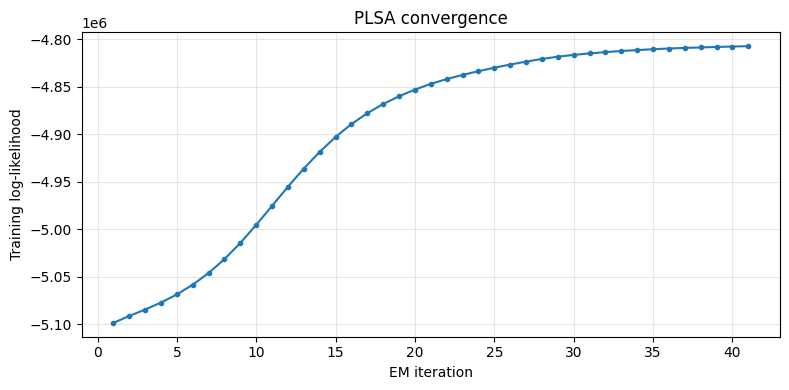

In [7]:
for topic_id, words in best_plsa.top_words(vocabulary, n=12).items():
    print(f"\nTopic {topic_id}:")
    print(", ".join(f"{word} ({prob:.3f})" for word, prob in words))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(best_plsa.log_likelihoods)+1),
         best_plsa.log_likelihoods, marker="o", markersize=3)
plt.xlabel("EM iteration")
plt.ylabel("Training log-likelihood")
plt.title("PLSA convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Controlled topic-boundary experiment

Generate artificial documents by sampling word tokens from source documents in known categories. We then infer topic mixtures with folding-in and compare the known source proportions with the estimated probabilities.

**Interpretation caution:** a source-word ratio is not guaranteed to equal a latent-topic probability. Topics can split a category or overlap categories. We therefore identify sports-associated and politics-associated topics from training-set category averages, and interpret the result as an experiment rather than ground truth equivalence.

In [8]:
sports_class = target_names.index("rec.sport.baseball")
politics_class = target_names.index("talk.politics.misc")

class_topic_means = np.vstack([
    theta_train[y_train == c].mean(axis=0)
    for c in range(len(target_names))
])
sports_topic = int(class_topic_means[sports_class].argmax())
politics_topic = int(class_topic_means[politics_class].argmax())

print("Sports-associated topic:", sports_topic)
print("Politics-associated topic:", politics_topic)
if sports_topic == politics_topic:
    print("Warning: both categories map to the same dominant topic; interpret estimates cautiously.")

def sample_token_ids(row):
    row = csr_matrix(row)
    return np.repeat(row.indices, row.data.astype(int))

def make_mixed_document(X_source, y_source, class_a, class_b,
                        ratio_a, rng, n_tokens=300):

    a_candidates = np.where((y_source == class_a) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]
    b_candidates = np.where((y_source == class_b) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]

    da = X_source[a_candidates[rng.integers(len(a_candidates))]]
    db = X_source[b_candidates[rng.integers(len(b_candidates))]]
    tokens_a = sample_token_ids(da)
    tokens_b = sample_token_ids(db)
    if len(tokens_a) == 0 or len(tokens_b) == 0:
        raise ValueError("A sampled source document had no in-vocabulary tokens.")
    n_a = int(round(n_tokens * ratio_a))
    n_b = n_tokens - n_a
    tokens = np.concatenate([
        rng.choice(tokens_a, size=n_a, replace=True),
        rng.choice(tokens_b, size=n_b, replace=True)
    ])
    counts = np.bincount(tokens, minlength=X_source.shape[1]).astype(float)
    return csr_matrix(counts.reshape(1, -1))

boundary_rng = np.random.default_rng(SEED + 77)
ratios = [0.9, 0.7, 0.5, 0.3, 0.1]
boundary_rows = []

for ratio in ratios:
    for replicate in range(20):
        mixed_X = make_mixed_document(
            X_train, y_train, sports_class, politics_class,
            ratio, boundary_rng, n_tokens=300
        )
        estimate = best_plsa.fold_in(mixed_X, max_iter=100)[0]
        boundary_rows.append({
            "source_category_a": "rec.sport.baseball",
            "source_category_b": "talk.politics.misc",
            "actual_sports_word_ratio": ratio,
            "actual_politics_word_ratio": 1-ratio,
            "estimated_sports_topic": estimate[sports_topic],
            "estimated_politics_topic": estimate[politics_topic],
            "replicate": replicate
        })

boundary_df = pd.DataFrame(boundary_rows)
boundary_summary = boundary_df.groupby("actual_sports_word_ratio").agg(
    estimated_sports_mean=("estimated_sports_topic", "mean"),
    estimated_sports_std=("estimated_sports_topic", "std"),
    estimated_politics_mean=("estimated_politics_topic", "mean"),
    estimated_politics_std=("estimated_politics_topic", "std")
).reset_index()
display(boundary_summary)

Sports-associated topic: 1
Politics-associated topic: 4


,actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0,0.1,0.182722,0.130048,0.413617,0.294741
1,0.3,0.371396,0.194139,0.304364,0.167164
2,0.5,0.553444,0.235891,0.163162,0.121129
3,0.7,0.675171,0.183936,0.095132,0.086187
4,0.9,0.729328,0.234877,0.067654,0.099233


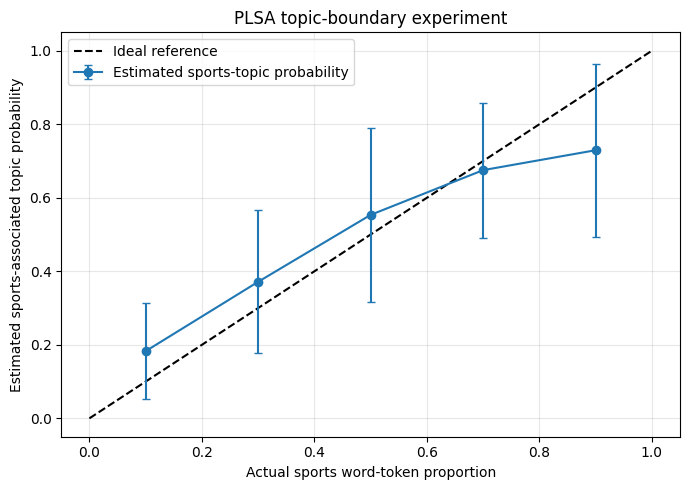

In [9]:
plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], "k--", label="Ideal reference")
plt.errorbar(
    boundary_summary["actual_sports_word_ratio"],
    boundary_summary["estimated_sports_mean"],
    yerr=boundary_summary["estimated_sports_std"],
    marker="o", capsize=3, label="Estimated sports-topic probability"
)
plt.xlabel("Actual sports word-token proportion")
plt.ylabel("Estimated sports-associated topic probability")
plt.title("PLSA topic-boundary experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 8. TF-IDF/VSM and LSI baselines

All baselines are fitted on training documents only. LSI uses truncated SVD on TF-IDF representations; it is a geometric low-rank representation, unlike PLSA's normalized probability distributions.

In [10]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=3000, min_df=3, max_df=0.90
)
X_train_tfidf = tfidf_vectorizer.fit_transform(docs_train_processed)
X_val_tfidf = tfidf_vectorizer.transform(docs_val_processed)
X_test_tfidf = tfidf_vectorizer.transform(docs_test_processed)
n_components = min(50, X_train_tfidf.shape[0]-1, X_train_tfidf.shape[1]-1)
lsi_model = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    Normalizer(copy=False)
)
lsi_train = lsi_model.fit_transform(X_train_tfidf)
lsi_val = lsi_model.transform(X_val_tfidf)
lsi_test = lsi_model.transform(X_test_tfidf)
print("TF-IDF train/validation/test:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)
print("LSI train/validation/test:", lsi_train.shape, lsi_val.shape, lsi_test.shape)


TF-IDF train/validation/test: (11307, 3000) (3769, 3000) (3770, 3000)
LSI train/validation/test: (11307, 50) (3769, 50) (3770, 50)


## 9. Retrieval and model-order comparison

We reuse the same 20 fixed category queries from the all-20 baseline. PLSA is evaluated with cosine similarity between folded-in topic mixtures and with query likelihood. For each K, the best of three random restarts is chosen by training log-likelihood. Validation MAP@10 selects K separately for each PLSA scoring method. The final test table reports all five predeclared K values alongside TF-IDF and LSI; test results are for comparison and are not used to tune K.


In [11]:
category_queries = {
    "alt.atheism": "atheism atheist religion belief",
    "comp.graphics": "computer graphics rendering image pixels",
    "comp.os.ms-windows.misc": "windows operating system microsoft files",
    "comp.sys.ibm.pc.hardware": "IBM PC hardware disk memory computer",
    "comp.sys.mac.hardware": "Apple Macintosh Mac hardware computer",
    "comp.windows.x": "X Window System display server windows",
    "misc.forsale": "for sale price shipping offer",
    "rec.autos": "car automobile engine dealer",
    "rec.motorcycles": "motorcycle bike riding helmet",
    "rec.sport.baseball": "baseball players team season game",
    "rec.sport.hockey": "hockey team NHL puck season",
    "sci.crypt": "cryptography encryption key security",
    "sci.electronics": "electronics circuit voltage resistor",
    "sci.med": "medical doctor disease treatment health",
    "sci.space": "space NASA spacecraft orbit planet",
    "soc.religion.christian": "Christian church Bible Jesus faith",
    "talk.politics.guns": "gun control firearms second amendment",
    "talk.politics.mideast": "Middle East Israel Arab Palestinian",
    "talk.politics.misc": "government election political policy",
    "talk.religion.misc": "religion religious belief faith",
}
assert set(category_queries) == set(target_names)

K_GRID = [2, 5, 8, 10, 20]
N_RESTARTS = 3
TOP_K = 10

def metrics_at_k(scores, labels, target, k=TOP_K):
    order = np.argsort(np.asarray(scores))[::-1]
    relevant = (np.asarray(labels) == target).astype(int)
    total_relevant = int(relevant.sum())
    selected = relevant[order[:k]]
    precision = float(selected.sum() / min(k, len(relevant)))
    recall = float(selected.sum() / total_relevant) if total_relevant else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    ranks = np.flatnonzero(selected) + 1
    ap = float(sum((i + 1) / rank for i, rank in enumerate(ranks)) /
               min(total_relevant, k)) if total_relevant else 0.0
    mrr = float(1 / ranks[0]) if len(ranks) else 0.0
    return {"Precision@10": precision, "Recall@10": recall, "F1@10": f1,
            "AP@10": ap, "MRR": mrr}

def evaluate_model(model, theta_docs, split_name, labels, processed_docs,
                   tfidf_docs, lsi_docs, k_topics):
    eligible = np.asarray([bool(text.strip()) for text in processed_docs])
    y_eval = np.asarray(labels)[eligible]
    theta_eval = theta_docs[eligible]
    tfidf_eval = tfidf_docs[eligible]
    lsi_eval = lsi_docs[eligible]
    rows = []
    for category, query_text in category_queries.items():
        target = target_names.index(category)
        processed_query = preprocess_texts([query_text])[0]
        q_counts = count_vectorizer.transform([processed_query]).astype(np.float64)
        q_tfidf = tfidf_vectorizer.transform([processed_query])
        q_lsi = lsi_model.transform(q_tfidf)
        q_theta = model.fold_in(q_counts, max_iter=100)
        scores = {
            "TF-IDF/VSM": cosine_similarity(q_tfidf, tfidf_eval).ravel(),
            "LSI": cosine_similarity(q_lsi, lsi_eval).ravel(),
            "PLSA cosine": cosine_similarity(q_theta, theta_eval).ravel(),
        }
        likelihood = np.zeros(len(y_eval), dtype=float)
        q_csr = csr_matrix(q_counts)
        for word_id, count in zip(q_csr.indices, q_csr.data):
            p_word_doc = theta_eval @ model.phi_[:, word_id]
            likelihood += count * np.log(np.maximum(p_word_doc, 1e-12))
        scores["PLSA query likelihood"] = likelihood
        for method, method_scores in scores.items():
            rows.append({"split": split_name, "K": k_topics,
                         "query_category": category, "query_text": query_text,
                         "method": method,
                         **metrics_at_k(method_scores, y_eval, target)})
    return rows

models_by_k = {}
model_order_rows = []
validation_rows = []
test_rows = []
for k_topics in K_GRID:
    print(f"\nFitting K={k_topics} with {N_RESTARTS} restarts")
    model, runs = train_plsa_restarts(
        X_train, n_topics=k_topics, n_restarts=N_RESTARTS,
        max_iter=80, tol=1e-4, base_seed=SEED + 100 * k_topics
    )
    models_by_k[k_topics] = model
    model_order_rows.append({
        "K": k_topics, "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "restart_count": len(runs),
    })
    theta_val_k = model.fold_in(X_val, max_iter=100)
    theta_test_k = model.fold_in(X_test, max_iter=100)
    validation_rows.extend(evaluate_model(
        model, theta_val_k, "validation", y_val, docs_val_processed,
        X_val_tfidf, lsi_val, k_topics
    ))
    test_rows.extend(evaluate_model(
        model, theta_test_k, "test", y_test, docs_test_processed,
        X_test_tfidf, lsi_test, k_topics
    ))

model_order_df = pd.DataFrame(model_order_rows)
validation_df = pd.DataFrame(validation_rows)
test_all_k_df = pd.DataFrame(test_rows)

validation_summary = validation_df.groupby(["K", "method"])[
    ["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]
].mean().reset_index()
test_plsa_df = test_all_k_df[test_all_k_df["method"].str.startswith("PLSA")]
test_baselines_df = test_all_k_df[
    (test_all_k_df["K"] == K_GRID[0]) &
    (test_all_k_df["method"].isin(["TF-IDF/VSM", "LSI"]))
]
test_summary = test_plsa_df.groupby(["K", "method"])[
    ["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]
].mean().reset_index()
baseline_summary = test_baselines_df.groupby("method")[
    ["Precision@10", "Recall@10", "F1@10", "AP@10", "MRR"]
].mean()

val_ll = validation_summary[validation_summary["method"] == "PLSA query likelihood"].sort_values(
    ["AP@10", "Precision@10"], ascending=False
)
val_cos = validation_summary[validation_summary["method"] == "PLSA cosine"].sort_values(
    ["AP@10", "Precision@10"], ascending=False
)
best_k_ll = int(val_ll.iloc[0]["K"])
best_k_cos = int(val_cos.iloc[0]["K"])

print("\nTraining fit and convergence:")
display(model_order_df)
print("\nValidation retrieval by K (use these to choose K):")
display(validation_summary.sort_values(["method", "K"]))
print(f"Validation-selected K for PLSA query likelihood: {best_k_ll}")
print(f"Validation-selected K for PLSA cosine: {best_k_cos}")
print("\nFinal held-out test baseline results:")
display(baseline_summary)
print("\nFinal held-out PLSA test results for every predeclared K:")
display(test_summary.sort_values(["method", "K"]))



Fitting K=2 with 3 restarts
Restart 1: final training log-likelihood=-4965485.858, iterations=39
Restart 2: final training log-likelihood=-4964490.034, iterations=25
Restart 3: final training log-likelihood=-4978175.107, iterations=51
Selected best training likelihood: -4964490.034

Fitting K=5 with 3 restarts
Restart 1: final training log-likelihood=-4820334.733, iterations=39
Restart 2: final training log-likelihood=-4822277.349, iterations=63
Restart 3: final training log-likelihood=-4812426.822, iterations=42
Selected best training likelihood: -4812426.822

Fitting K=8 with 3 restarts
Restart 1: final training log-likelihood=-4742009.612, iterations=51
Restart 2: final training log-likelihood=-4728755.358, iterations=62
Restart 3: final training log-likelihood=-4730621.843, iterations=54
Selected best training likelihood: -4728755.358

Fitting K=10 with 3 restarts
Restart 1: final training log-likelihood=-4698158.988, iterations=54
Restart 2: final training log-likelihood=-4700025

,K,iterations,train_log_likelihood,restart_count
0,2,25,-4.964490e+06,3
1,5,42,-4.812427e+06,3
2,8,62,-4.728755e+06,3
3,10,55,-4.687288e+06,3
4,20,62,-4.558363e+06,3



Validation retrieval by K (use these to choose K):


,K,method,Precision@10,Recall@10,F1@10,AP@10,MRR
0,2,LSI,0.655,0.034870,0.066207,0.587792,0.818056
4,5,LSI,0.655,0.034870,0.066207,0.587792,0.818056
8,8,LSI,0.655,0.034870,0.066207,0.587792,0.818056
12,10,LSI,0.655,0.034870,0.066207,0.587792,0.818056
16,20,LSI,0.655,0.034870,0.066207,0.587792,0.818056
1,2,PLSA cosine,0.095,0.005153,0.009773,0.034871,0.238115
5,5,PLSA cosine,0.155,0.008592,0.016266,0.064881,0.311865
9,8,PLSA cosine,0.250,0.013700,0.025956,0.161185,0.492500
13,10,PLSA cosine,0.300,0.016733,0.031663,0.160423,0.383948
17,20,PLSA cosine,0.500,0.027268,0.051686,0.334970,0.553333


Validation-selected K for PLSA query likelihood: 20
Validation-selected K for PLSA cosine: 20

Final held-out test baseline results:


,Precision@10,Recall@10,F1@10,AP@10,MRR
method,,,,,
LSI,0.730,0.039694,0.075260,0.642089,0.816667
TF-IDF/VSM,0.735,0.039846,0.075564,0.656034,0.966667



Final held-out PLSA test results for every predeclared K:


,K,method,Precision@10,Recall@10,F1@10,AP@10,MRR
0,2,PLSA cosine,0.090,0.004798,0.009109,0.034276,0.214702
2,5,PLSA cosine,0.155,0.008626,0.016326,0.058831,0.269921
4,8,PLSA cosine,0.255,0.013863,0.026274,0.139423,0.418333
6,10,PLSA cosine,0.325,0.017739,0.033621,0.208286,0.510417
8,20,PLSA cosine,0.520,0.028272,0.053607,0.346331,0.639286
1,2,PLSA query likelihood,0.100,0.005419,0.010272,0.043998,0.182917
3,5,PLSA query likelihood,0.200,0.011075,0.020972,0.121651,0.309841
5,8,PLSA query likelihood,0.270,0.014738,0.027927,0.157506,0.427361
7,10,PLSA query likelihood,0.330,0.017905,0.033943,0.210633,0.493869
9,20,PLSA query likelihood,0.465,0.025608,0.048510,0.288026,0.647976


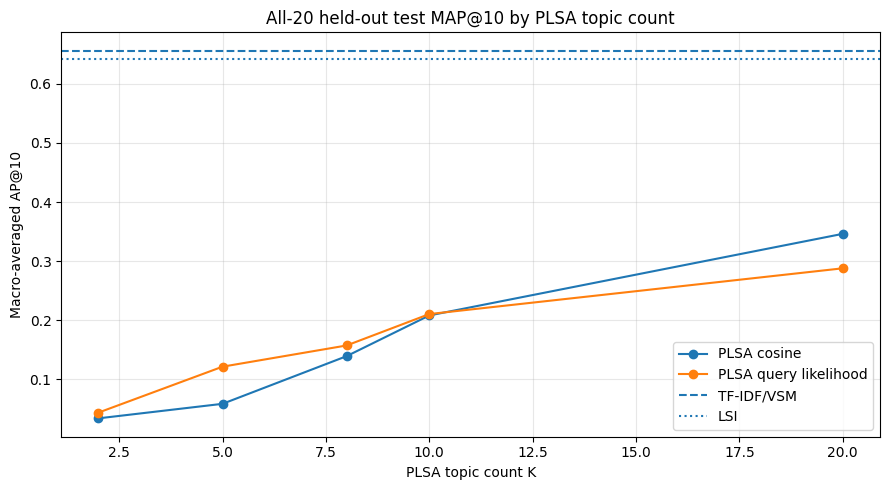

In [12]:

test_plsa_plot = test_summary.pivot(index="K", columns="method", values="AP@10")
test_plsa_plot.plot(marker="o", figsize=(9, 5))
plt.axhline(baseline_summary.loc["TF-IDF/VSM", "AP@10"], linestyle="--", label="TF-IDF/VSM")
plt.axhline(baseline_summary.loc["LSI", "AP@10"], linestyle=":", label="LSI")
plt.title("All-20 held-out test MAP@10 by PLSA topic count")
plt.xlabel("PLSA topic count K")
plt.ylabel("Macro-averaged AP@10")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Model-order interpretation

The preceding sweep compares K = 2, 5, 8, 10, and 20 on identical data and queries. Use validation MAP@10 to select K; interpret test scores as a predeclared sensitivity comparison, not as a second opportunity to tune. Training log-likelihood is included as a fit/convergence diagnostic and is not itself evidence of better retrieval or generalization.


In [13]:

plsa_by_category = test_plsa_df.pivot_table(
    index=["K", "query_category"], columns="method", values="AP@10"
).reset_index()
display(plsa_by_category)



method,K,query_category,PLSA cosine,PLSA query likelihood
0,2,alt.atheism,0.000000,0.000000
1,2,comp.graphics,0.090000,0.000000
2,2,comp.os.ms-windows.misc,0.083333,0.000000
3,2,comp.sys.ibm.pc.hardware,0.122222,0.096667
4,2,comp.sys.mac.hardware,0.012500,0.000000
...,...,...,...,...
95,20,soc.religion.christian,0.039286,0.069286
96,20,talk.politics.guns,0.321667,0.259524
97,20,talk.politics.mideast,0.637778,0.196190
98,20,talk.politics.misc,0.421667,0.240000


## 11. Optional extension: tempered E-step (exploratory)

Hofmann's paper introduces Tempered EM as an entropy-regularized fitting procedure and recommends evaluating held-out performance while changing the inverse temperature. The `beta` option in the class is a simplified tempered E-step, **not a full reproduction of the paper's TEM schedule**. Treat this section as exploratory only, and don't claim that it fully implements TEM.

For a proper TEM experiment, start with standard EM at beta=1, lower beta in small steps, run tempered iterations, and monitor held-out predictive likelihood/perplexity; stop when held-out performance deteriorates. A rigorous implementation should define and document the exact schedule and stopping rule.

In [14]:
tempered_rows = []
for beta in [1.0, 0.9, 0.8, 0.7]:
    model = PLSA(
        n_topics=K, max_iter=80, tol=1e-4,
        random_state=SEED, beta=beta
    ).fit(X_train)
    tempered_rows.append({
        "beta": beta,
        "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "warning": "Simplified tempered E-step; not full TEM"
    })

display(pd.DataFrame(tempered_rows))


,beta,iterations,train_log_likelihood,warning
0,1.0,39,-4.825154e+06,Simplified tempered E-step; not full TEM
1,0.9,46,-4.817885e+06,Simplified tempered E-step; not full TEM
2,0.8,51,-4.834226e+06,Simplified tempered E-step; not full TEM
3,0.7,3,-5.094637e+06,Simplified tempered E-step; not full TEM


## 12. Keep results in the notebook

Model-order, validation, and held-out test tables are displayed inline. No experiment CSV files are written.


## 13. Limitations to state in the report

1. PLSA is trained on all 20 categories, but learned topics do not necessarily correspond one-to-one to the 20 human labels.
2. Synthetic source-word proportions in the baseball/politics boundary experiment are not identical to latent-topic probabilities.
3. Selecting the best training likelihood does not guarantee the best retrieval performance.
4. Category labels are only a proxy for relevance; manually judged query-document relevance would be stronger.
5. The 20 representative queries are manually authored, and query wording can affect ranking. Include the query set in the report.
6. Hofmann's paper used MED, CRAN, CACM and CISI collections; this project uses 20 Newsgroups and does not reproduce the paper's exact numerical results.
7. The optional beta experiment is a simplified tempered E-step unless the full TEM schedule and held-out stopping criterion are implemented.
8. A capped vocabulary and sparse count matrix are used to keep computation manageable.


## 14. Reproducibility and interpretation checks

Before interpreting the comparison, verify:

1. **Preprocessing parity:** PLSA, TF-IDF, LSI, and query text all use `preprocess_texts`; vocabulary fitting uses training documents only.
2. **Empty documents/queries:** report the number of empty documents after preprocessing. Empty test documents cannot provide meaningful evidence for any retrieval method; report their count and consider excluding them consistently from retrieval evaluation (while retaining original labels/index mapping).
3. **PLSA topic interpretation:** topic IDs are arbitrary. Identify sports/politics topics by average training-document topic probabilities, then inspect top words and example documents before naming them.
4. **Boundary experiment:** the input ratio is the proportion of sampled tokens sourced from each category, not a guarantee that every token is category-exclusive. Shared vocabulary and imperfect learned topics explain deviations from the ideal line.
5. **Model order:** training log-likelihood generally improves with larger K; do not select K from training likelihood alone. Consider topic coherence/interpretability and held-out likelihood or retrieval results.
6. **No claims from stale outputs:** after changing preprocessing or vectorizer settings, rerun all cells from the top so every table and plot reflects the same code state.
